# Red Cedar — Quick Start

The basic Red Cedar workflow on your own data, the same steps as the Quick Start page of the documentation:
1. Train a quantum model on a CSV file
2. Check the quality of the training
3. Infer the class of new data the model has never seen
4. See which input features the model relies on

The data is the Wisconsin breast cancer dataset (WDBC), split once into two files in `data/`: `wdbc_train.csv` (455 rows) to train on, and `wdbc_new.csv` (114 rows) to predict. Each row is a tumor sample: 30 measurements, then the diagnosis in the last column, `M` (malignant) or `B` (benign).

All computation happens on the server; this notebook sends requests and plots the results. To explore a dataset before training (PCA, mutual information, qubit estimates) see `02_dataset_analysis.ipynb`. All SDK functions are described in the [User Guide](https://coherent-computing.github.io/redcedar/user_guide/).

In [1]:
import redcedar
import matplotlib.pyplot as plt

# Connect to the server
# Reads REDCEDAR_URL and REDCEDAR_API_KEY from environment, or pass explicitly:
# client = redcedar.connect(url="http://127.0.0.1:8002", api_key="your-key")
# With the Red Cedar source installed (pip install -e), local mode calls it directly:
# client = redcedar.connect(local=True)
client = redcedar.connect()
print(f"Red Cedar SDK v{redcedar.__version__}")
status = client.status()
print(f"Server: {client.url or 'local mode, in this process'} (version {status['server_version'] or 'unknown'}, ok={status['ok']})")

train_file = "data/wdbc_train.csv"   # 455 rows to train on
new_file = "data/wdbc_new.csv"       # 114 rows the model never sees in training

Red Cedar SDK v0.93.0
Server: http://127.0.0.1:8002 (version 0.92-18-g1706a0dc-dirty, ok=True)


## 1. Train a model

`training.run()` takes the path of a CSV file: the SDK uploads it and the server trains on it. The last column is the one to predict; a header row is optional.

Training runs layer by layer: each layer adds a set of operators to the circuit and starts from the parameters the previous layer found. Here we use 6 qubits and 2 layers, which trains in about a minute. `seed` fixes the starting parameters, so the run can be repeated exactly.

At the end of each layer the server tests the model on rows it set aside from the file (20% by default); those results come back in `result["validation"]`.

In [2]:
result = client.training.run(train_file, verbose=True, settings={
    "num_qubits": 6,
    "min_layers": 1,
    "max_layers": 2,
    "seed": 123,
})

train_id = result["train_id"]
print(f"\nModel ID: {train_id}")
print(f"Training time: {result['elapsed_seconds']}s")
for layer, v in result["validation"].items():
    print(f"Layer {layer}: test accuracy {v['test_accuracy']:.1%}, test loss {v['test_loss']:.4f}")

  [  5%] Layer 1/2...
  Layer 1: test accuracy 87.9%
  [ 50%] Layer 2/2..........
  Layer 2: test accuracy 87.9%
  [100%] Done.

Model ID: bce76a0e-d4b1-4fcc-a576-623fbfaef945
Training time: 28.5s
Layer 1: test accuracy 87.9%, test loss 0.4675
Layer 2: test accuracy 87.9%, test loss 0.4760


## 2. Training quality

While the model trains, Red Cedar measures its loss and accuracy on the training rows after every parameter update, in each layer. These measurements come back with the result, in `result["history"]`, so you can see how the training progressed.

- **Training loss** says how far the model's answers are from the right ones. For each row the model gives a probability to every class; the loss is built from 1 minus the probability of the correct class, averaged over the training rows. It goes down as the model becomes more sure of the right answers.
- **Training accuracy** is the share of training rows whose correct class is the one the model finds most likely.

The test results printed above are the same two measures on the rows held back, which the model never trains on. The [User Guide](https://coherent-computing.github.io/redcedar/user_guide/#training-loss-and-accuracy) has the details.

The plots below show them, one curve per layer; the dashed line marks where a new layer starts. A falling loss and a rising accuracy show the model is learning, and a curve that levels off means that layer has gone as far as it can.

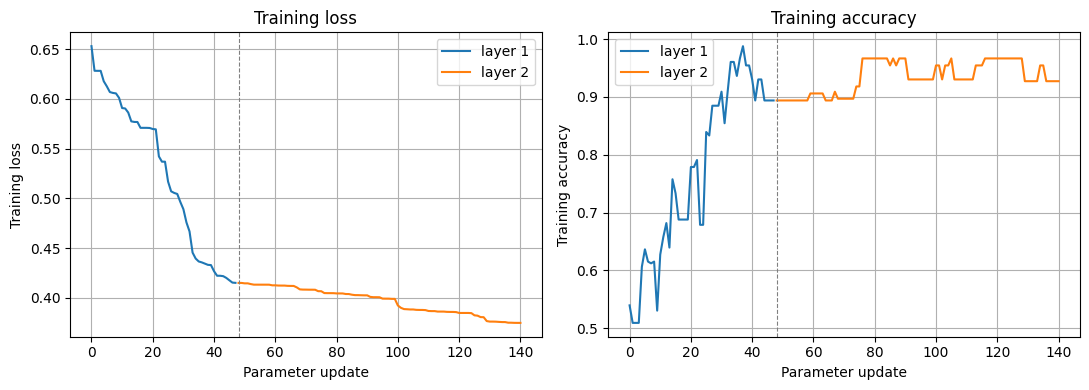

In [3]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
start = 0
for layer, points in result["history"].items():
    steps = range(start, start + len(points))
    ax_loss.plot(steps, [p["train_loss"] for p in points], label=f"layer {layer}")
    ax_acc.plot(steps, [p["train_accuracy"] for p in points], label=f"layer {layer}")
    if start:
        ax_loss.axvline(start, color="gray", ls="--", lw=0.8)
        ax_acc.axvline(start, color="gray", ls="--", lw=0.8)
    start += len(points)

ax_loss.set(xlabel="Parameter update", ylabel="Training loss", title="Training loss")
ax_acc.set(xlabel="Parameter update", ylabel="Training accuracy", title="Training accuracy")
for ax in (ax_loss, ax_acc):
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Infer the class of new data

With the model trained, you can apply it to new data whose class is unknown: for each row, the model infers the class from the row's features. Here the new data is `wdbc_new.csv`, 114 tumor samples the model never saw in training, and for each one the model infers whether it is malignant (`M`) or benign (`B`), with the probability of each class.

`inference.run()` takes the model's ID and the file, and matches the file's columns to the training file's by name. This file still has the diagnosis column, so we can check the answers: the server reports the accuracy, and the code below compares the first rows. With truly new data you would leave that column out. `output=` writes the rows and their inferred class to a CSV file.

  [100%] Done.

Accuracy on 114 new rows: 86.0%
Rows and predictions written to wdbc_new_predictions.csv

First 5 rows:
  actual M, predicted M  (B: 26%, M: 74%)
  actual M, predicted M  (B: 21%, M: 79%)
  actual M, predicted M  (B: 34%, M: 66%)
  actual M, predicted M  (B: 22%, M: 78%)
  actual B, predicted B  (B: 70%, M: 30%)


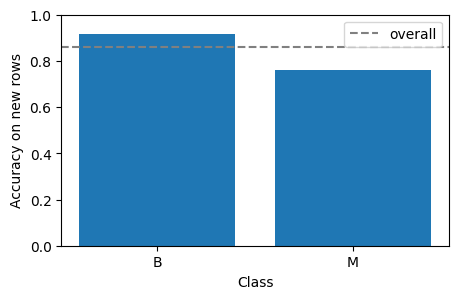

In [4]:
predictions = client.inference.run(train_id, new_file, output="wdbc_new_predictions.csv", verbose=True)

print(f"\nAccuracy on {predictions['rows']} new rows: {predictions['accuracy']:.1%}")
print("Rows and predictions written to wdbc_new_predictions.csv")

# Compare with the diagnosis in the file
import csv
with open(new_file, newline="") as f:
    actual = [row["diagnosis"] for row in csv.DictReader(f)]
rows = list(zip(actual, predictions["predictions"]))

print("\nFirst 5 rows:")
for a, p in rows[:5]:
    probs = ", ".join(f"{c}: {v:.0%}" for c, v in p["probabilities"].items())
    print(f"  actual {a}, predicted {p['prediction']}  ({probs})")

classes = sorted(set(actual))
accuracy = [sum(str(p["prediction"]) == c for a, p in rows if a == c) / actual.count(c) for c in classes]
plt.figure(figsize=(5, 3))
plt.bar(classes, accuracy)
plt.axhline(predictions["accuracy"], color="gray", ls="--", label="overall")
plt.ylim(0, 1)
plt.xlabel("Class")
plt.ylabel("Accuracy on new rows")
plt.legend()
plt.show()

## 4. Which features the model relies on

Explainable AI maps each data qubit back to the input feature it encodes and measures how much that qubit influences the prediction.

  [100%] Done.
  Qubit 0: mean_radius (importance 76.3%)
  Qubit 1: mean_radius (importance 3.7%)
  Qubit 2: worst_concave_points (importance 14.3%)
  Qubit 3: mean_perimeter (importance 38.1%)
  Qubit 4: worst_compactness (importance 0.0%)


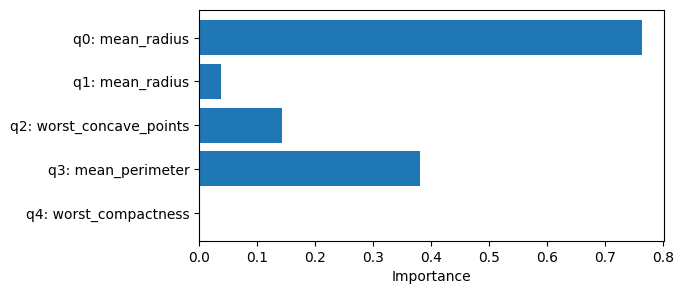

In [5]:
explanation = client.explainable.run(train_id, verbose=True)

qubits = explanation["qubit_map"]
for q in qubits:
    print(f"  Qubit {q['qubit']}: {q['feature_name']} (importance {q['importance']:.1%})")

plt.figure(figsize=(6, 3))
plt.barh([f"q{q['qubit']}: {q['feature_name']}" for q in qubits], [q["importance"] for q in qubits])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.show()

## Next steps

- `02_dataset_analysis.ipynb`: explore a dataset before training, or analyze your own CSV file
- `03_training_settings.ipynb`: settings you can change, one section per setting
- `04_training_in_depth.ipynb`: layers, testing on the rows the server set aside (`training.evaluate()`), test accuracy over the course of training, choosing the data, reusing models, stopping a job